# Task 1: Time-series Preprocessing and Exploratory Analysis

**Project question:** Can we use past sales data to predict the total value of products customers will order over the next seven days?

This notebook completes **Task 1 only**: understanding and preprocessing the data, answering six analytical questions, and training and tuning a forecasting model. Database design, APIs, and the forecast script (Tasks 2–4) are intentionally left to the other team members.

**Target:** daily sum of item `price`, in Brazilian reais (BRL), assigned to the order's purchase date. We forecast seven individual days and sum them for the seven-day total. Freight is excluded. This is recorded merchandise value, not profit or net revenue. All recorded orders with item rows are included regardless of their eventual status, because final status is not known at purchase time. Orders without items have unknown merchandise value and are reported rather than assigned a fabricated price.

Source: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). Check the source's licensing and attribution requirements before redistributing data.

## Run on Kaggle or Google Colab

- **Kaggle:** Create a notebook, use **Add Input** to attach the Olist dataset, and upload this notebook. Files are discovered under `/kaggle/input`.
- **Colab:** Upload this notebook, then run the upload cell and select `olist_orders_dataset.csv` and `olist_order_items_dataset.csv` from your download. Only these two CSVs are required.
- Run cells in order. Outputs are saved to `/kaggle/working/olist_task1_outputs` on Kaggle or `/content/olist_task1_outputs` on Colab. The final cell can download them as a ZIP in Colab.

No local paths, database servers, API keys, or GPU are required. The standard Kaggle/Colab Python environments normally include the libraries below. If an import fails, install the named package in a new notebook cell using `%pip install pandas numpy matplotlib seaborn scikit-learn joblib` and restart the session.

In [2]:
from pathlib import Path
import sys, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
import sklearn
import joblib

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = Path("/kaggle/input").exists()
OUT = Path("/kaggle/working" if IS_KAGGLE else "/content") / "olist_task1_outputs"
OUT.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT)
print("pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

Output folder: /kaggle/working/olist_task1_outputs
pandas: 2.3.3 scikit-learn: 1.6.1


## A. Understand and prepare the dataset
### 1. Load the two source tables
Orders provide timestamps and statuses. Order items provide product prices and freight charges. Their relationship is one order to many items; aggregating items before joining prevents duplicated order counts.

In [3]:
if IS_COLAB:
    from google.colab import files
    required = ["olist_orders_dataset.csv", "olist_order_items_dataset.csv"]
    if not all((Path("/content") / name).exists() for name in required):
        print("Select the two required CSV files.")
        files.upload()

ROOT = Path("/kaggle/input") if IS_KAGGLE else Path("/content")
def locate(name):
    matches = sorted(ROOT.rglob(name))
    if not matches:
        raise FileNotFoundError(f"Attach/upload {name}, then rerun this cell.")
    if len(matches) > 1:
        raise ValueError(f"Multiple copies of {name} found: {matches}. Keep one dataset copy.")
    return matches[0]

orders = pd.read_csv(locate("olist_orders_dataset.csv"))
items = pd.read_csv(locate("olist_order_items_dataset.csv"))
display(pd.DataFrame({"table": ["orders", "order_items"],
                      "rows": [len(orders), len(items)],
                      "columns": [orders.shape[1], items.shape[1]]}))
display(orders.head(3), items.head(3))

,table,rows,columns
0,orders,99441,8
1,order_items,112650,7


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


### 2. Audit missing values, duplicates, timestamps, and prices

Missing purchase dates cannot be placed on the time axis, so those orders are excluded and counted. Missing/invalid item prices cannot be reliably imputed from other products; their entire order is excluded from the monetary target and reported. Missing delivery/approval timestamps are retained: they are not needed for this target and may reflect unfinished orders. Exact duplicate rows are removed; conflicting primary keys stop execution for investigation. Zero prices are retained and reported; negative prices are treated as invalid. Timestamps are interpreted as recorded, without assuming an undocumented timezone.

In [4]:
missing = pd.concat([orders.isna().sum().rename("orders"),
                     items.isna().sum().rename("items")], axis=1).fillna(0).astype(int)
display(missing)
print("Exact duplicate rows:", {"orders": int(orders.duplicated().sum()),
                                "items": int(items.duplicated().sum())})
orders = orders.drop_duplicates().copy()
items = items.drop_duplicates().copy()
assert orders["order_id"].notna().all() and orders["order_id"].is_unique
assert not items.duplicated(["order_id", "order_item_id"]).any()
assert items["order_id"].notna().all()
assert items["order_id"].isin(orders["order_id"]).all(), "Investigate orphan item rows"
for col in orders.columns:
    if col.endswith("_at") or "timestamp" in col or "date" in col:
        orders[col] = pd.to_datetime(orders[col], errors="coerce")
for col in ["price", "freight_value"]:
    items[col] = pd.to_numeric(items[col], errors="coerce")
invalid_price = items["price"].isna() | ~np.isfinite(items["price"]) | items["price"].lt(0)
bad_orders = set(items.loc[invalid_price, "order_id"])
print("Invalid-price item rows:", int(invalid_price.sum()))
print("Orders excluded for invalid prices:", len(bad_orders))
print("Zero-price items retained:", int(items["price"].eq(0).sum()))
print("Missing/invalid purchase timestamps:", int(orders.order_purchase_timestamp.isna().sum()))
print("Purchase range:", orders.order_purchase_timestamp.min(), "to", orders.order_purchase_timestamp.max())
display(orders.order_status.value_counts().rename_axis("status").to_frame("orders"))

,orders,items
order_id,0,0
customer_id,0,0
order_status,0,0
order_purchase_timestamp,0,0
order_approved_at,160,0
order_delivered_carrier_date,1783,0
order_delivered_customer_date,2965,0
order_estimated_delivery_date,0,0
order_item_id,0,0
product_id,0,0


Exact duplicate rows: {'orders': 0, 'items': 0}
Invalid-price item rows: 0
Orders excluded for invalid prices: 0
Zero-price items retained: 0
Missing/invalid purchase timestamps: 0
Purchase range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


,orders
status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


### 3. Establish temporal coverage and granularity

Raw observations are irregular order events, not daily measurements. The following chart checks coverage before aggregation. We use **1 January 2017–31 August 2018** as an initial analysis window because the downloaded dataset has sparse observations at both ends. August 2018 is retained as a calendar month but should still be checked for end-of-collection effects. Sparse edge months are not evidence of a business collapse. Daily intervals provide enough observations for short-horizon forecasting; fewer than two years limits conclusions about annual seasonality.

,orders
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


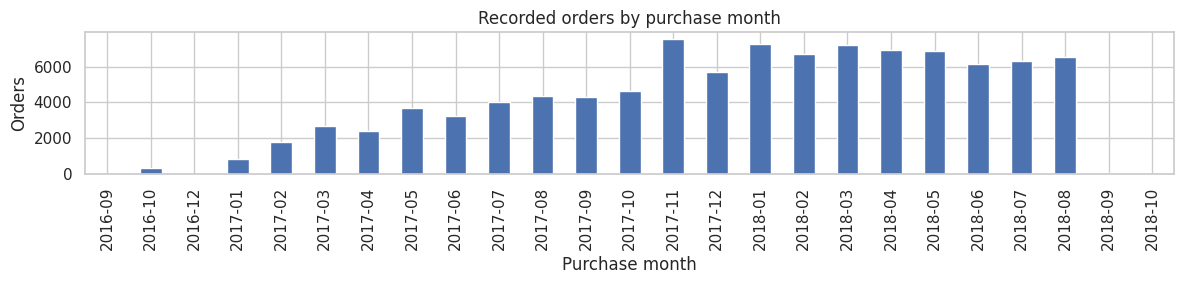

In [5]:
monthly_counts = orders.groupby(orders.order_purchase_timestamp.dt.to_period("M")).size()
display(monthly_counts.to_frame("orders"))
monthly_counts.plot.bar(figsize=(12, 3), title="Recorded orders by purchase month")
plt.ylabel("Orders"); plt.xlabel("Purchase month"); plt.tight_layout(); plt.show(); plt.close("all")
START, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-08-31")

In [6]:
valid_items = items.loc[~items.order_id.isin(bad_orders)].copy()
per_order = valid_items.groupby("order_id").agg(
    merchandise_value=("price", "sum"), item_count=("order_item_id", "size"))
# Keep all orders for the coverage audit; only known monetary values enter the target.
joined = orders.merge(per_order, on="order_id", how="left", validate="one_to_one")
print("Orders without usable item values:", int(joined.merchandise_value.isna().sum()))
joined["date"] = joined.order_purchase_timestamp.dt.normalize()
in_window = joined.loc[joined.date.between(START, END)].copy()
print("In-window orders without item values:", int(in_window.merchandise_value.isna().sum()))
known = in_window.dropna(subset=["merchandise_value"])
daily = known.groupby("date").agg(sales_value=("merchandise_value", "sum"),
    order_count=("order_id", "size"), item_count=("item_count", "sum"))
calendar = pd.date_range(START, END, freq="D", name="date")
absent = calendar.difference(daily.index)
print("Days with no known item-bearing orders:", len(absent), list(absent[:10]))
# A zero represents no recorded valid merchandise on that date, not verified zero demand.
daily = daily.reindex(calendar, fill_value=0)
daily["average_order_value"] = daily.sales_value.div(daily.order_count.replace(0, np.nan))
assert daily.index.is_unique and daily.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all()
assert daily.sales_value.notna().all() and daily.sales_value.ge(0).all()
assert np.isclose(daily.sales_value.sum(), known.merchandise_value.sum())
display(daily.head(), daily.describe().round(2))

Orders without usable item values: 775
In-window orders without item values: 739
Days with no known item-bearing orders: 6 [Timestamp('2017-01-01 00:00:00'), Timestamp('2017-01-02 00:00:00'), Timestamp('2017-01-03 00:00:00'), Timestamp('2017-01-04 00:00:00'), Timestamp('2018-08-30 00:00:00'), Timestamp('2018-08-31 00:00:00')]


,sales_value,order_count,item_count,average_order_value
date,,,,
2017-01-01,0.0,0,0.0,NaN
2017-01-02,0.0,0,0.0,NaN
2017-01-03,0.0,0,0.0,NaN
2017-01-04,0.0,0,0.0,NaN
2017-01-05,396.9,32,32.0,12.403125


,sales_value,order_count,item_count,average_order_value
count,608.00,608.00,608.00,602.00
mean,22272.55,161.76,184.67,139.44
std,12539.68,90.92,105.40,27.88
min,0.00,0.00,0.00,12.40
25%,13366.19,101.75,115.75,122.95
50%,20714.02,149.50,170.50,134.94
75%,29608.42,216.25,247.75,149.81
max,152653.74,1166.00,1366.00,337.98


**Missing-day policy:** inserted days contain zero *recorded* sales and counts. This is acceptable only as a description of this extract; missing reporting and true zero activity cannot be distinguished from these files. Investigate any printed missing dates before using the series operationally. Average order value remains missing when the denominator is zero. No forward-fill is applied to sales and no price imputation is performed.

### 4. Numerical distributions and outliers
Histograms and percentiles show skew and scale. Large orders may be real, so we retain them rather than automatically clipping the forecast target. Price and freight distributions are item-level; daily sales are day-level.

,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
50%,74.99,16.26
90%,229.80,34.04
95%,349.90,45.12
99%,890.00,84.52
max,6735.00,409.68


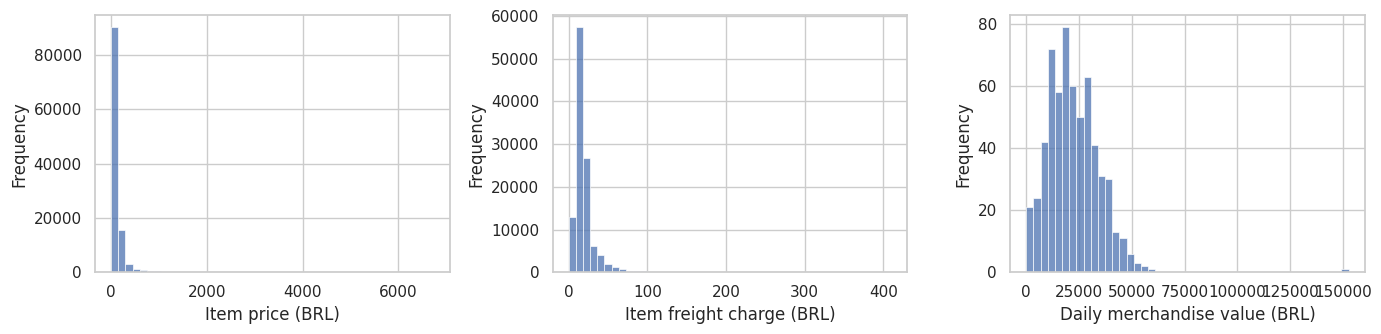

Daily sales median: 20714.01 mean: 22272.55 skewness: 2.12


In [7]:
display(items[["price", "freight_value"]].describe(percentiles=[.5, .9, .95, .99]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (label, values) in zip(axes, [("Item price (BRL)", items.price),
    ("Item freight charge (BRL)", items.freight_value), ("Daily merchandise value (BRL)", daily.sales_value)]):
    sns.histplot(values.dropna(), bins=45, ax=ax)
    ax.set_xlabel(label); ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show(); plt.close("all")
print("Daily sales median:", round(daily.sales_value.median(), 2),
      "mean:", round(daily.sales_value.mean(), 2),
      "skewness:", round(daily.sales_value.skew(), 2))

## B. Six analytical questions
Each question has a visualization and a data-driven interpretation generated from the loaded data. These are descriptive associations, not proof of causality. Questions 3 and 4 explicitly examine **lagged values and moving averages**. Historical summaries in this section describe the full window; predictive features and tuning later use only information available at each forecast origin.

### Q1. Does daily merchandise value show a rising or falling pattern?
A trailing 28-day mean smooths short-term variation without using future observations.

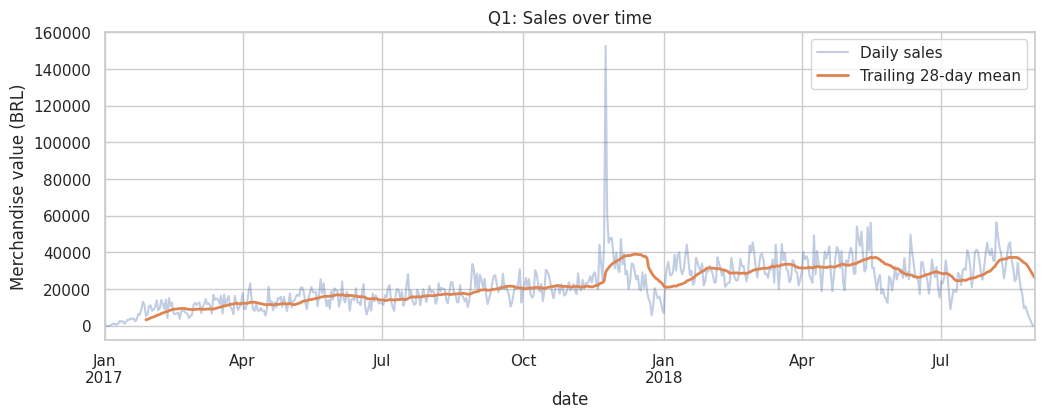

**Interpretation:** The first 28 days average BRL 3,283.50, versus BRL 26,199.82 in the last 28 days (+697.9%). This compares the endpoints, rather than establishing a uniform trend. The smoothed curve distinguishes sustained changes from isolated spikes; business growth, seasonality, and collection coverage can all affect it.

In [8]:
rolling28 = daily.sales_value.rolling(28, min_periods=28).mean()
ax = daily.sales_value.plot(figsize=(12, 4), alpha=.35, label="Daily sales")
rolling28.plot(ax=ax, linewidth=2, label="Trailing 28-day mean")
plt.ylabel("Merchandise value (BRL)"); plt.title("Q1: Sales over time"); plt.legend(); plt.show(); plt.close("all")
first, last = daily.sales_value.iloc[:28].mean(), daily.sales_value.iloc[-28:].mean()
change = 100 * (last / first - 1) if first else np.nan
display(Markdown(f"**Interpretation:** The first 28 days average BRL {first:,.2f}, versus BRL {last:,.2f} in the last 28 days ({change:+.1f}%). This compares the endpoints, rather than establishing a uniform trend. The smoothed curve distinguishes sustained changes from isolated spikes; business growth, seasonality, and collection coverage can all affect it."))

### Q2. Does merchandise value vary by day of the week?
Compare distributions as well as means so that unusually large days do not define the entire conclusion.

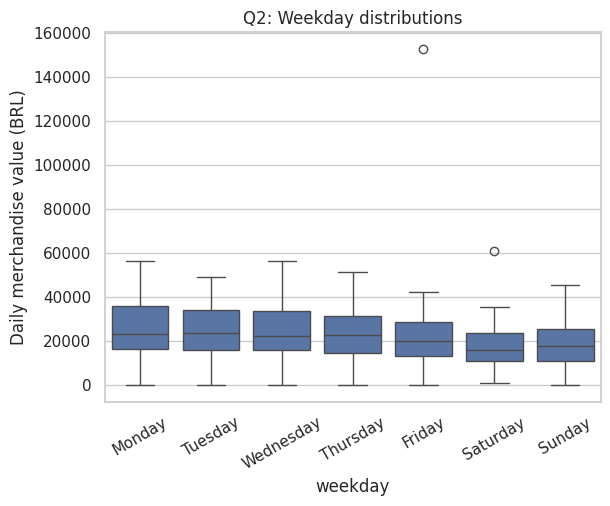

,mean_sales_brl
weekday,
Monday,25591.40
Tuesday,24858.70
Wednesday,24201.15
Thursday,23109.43
Friday,22473.42
Saturday,17390.42
Sunday,18227.23


**Interpretation:** Monday has the highest observed mean (BRL 25,591.40); Saturday has the lowest (BRL 17,390.42). Box overlap and outliers show how variable this pattern is. Calendar composition and growth may confound these averages, so weekday features must still demonstrate value on later unseen dates.

In [9]:
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_frame = daily.assign(weekday=daily.index.day_name())
sns.boxplot(data=weekday_frame, x="weekday", y="sales_value", order=weekdays)
plt.xticks(rotation=30); plt.ylabel("Daily merchandise value (BRL)"); plt.title("Q2: Weekday distributions"); plt.show(); plt.close("all")
weekday_means = weekday_frame.groupby("weekday").sales_value.mean().reindex(weekdays)
display(weekday_means.round(2).to_frame("mean_sales_brl"))
display(Markdown(f"**Interpretation:** {weekday_means.idxmax()} has the highest observed mean (BRL {weekday_means.max():,.2f}); {weekday_means.idxmin()} has the lowest (BRL {weekday_means.min():,.2f}). Box overlap and outliers show how variable this pattern is. Calendar composition and growth may confound these averages, so weekday features must still demonstrate value on later unseen dates."))

### Q3. Are sales related to sales 1, 7, 14, or 28 days earlier? (Lagged features)
Autocorrelation measures linear association between today's sales and earlier sales. A weekly lag can motivate a seasonal baseline; shared trends can also produce high correlations.

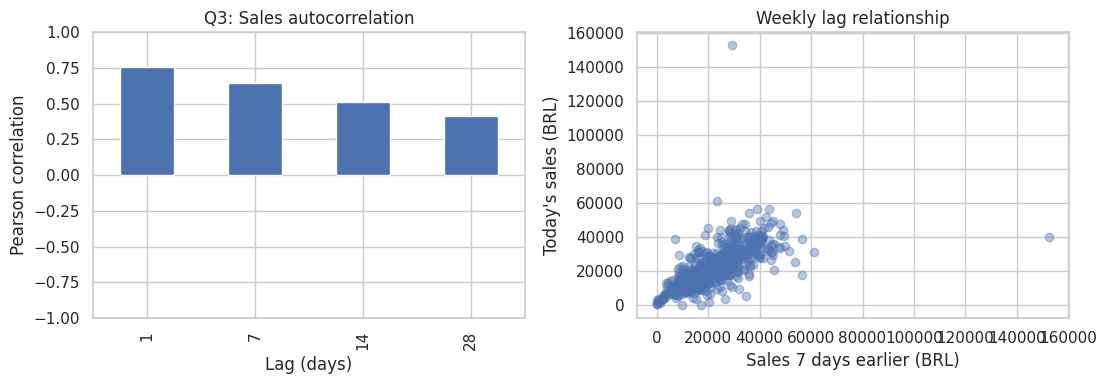

**Interpretation:** The 7-day correlation is 0.645. Of the tested lags, 1 days has the largest absolute correlation (0.754). This supports testing lag features, but does not guarantee forecast accuracy: trend and extreme sales days can influence the association.

In [10]:
lags = [1, 7, 14, 28]
lag_corr = pd.Series({lag: daily.sales_value.corr(daily.sales_value.shift(lag)) for lag in lags})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lag_corr.plot.bar(ax=axes[0], ylim=(-1, 1), title="Q3: Sales autocorrelation")
axes[0].set_xlabel("Lag (days)"); axes[0].set_ylabel("Pearson correlation")
axes[1].scatter(daily.sales_value.shift(7), daily.sales_value, alpha=.4)
axes[1].set(xlabel="Sales 7 days earlier (BRL)", ylabel="Today's sales (BRL)", title="Weekly lag relationship")
plt.tight_layout(); plt.show(); plt.close("all")
strongest = lag_corr.abs().idxmax()
display(Markdown(f"**Interpretation:** The 7-day correlation is {lag_corr.loc[7]:.3f}. Of the tested lags, {strongest} days has the largest absolute correlation ({lag_corr.loc[strongest]:.3f}). This supports testing lag features, but does not guarantee forecast accuracy: trend and extreme sales days can influence the association."))

### Q4. How informative are the previous 7-day and 28-day moving averages?
Shift by one day **before** computing means, so today's target never enters its own explanatory feature. These are one-day historical associations, not seven-day validation results.

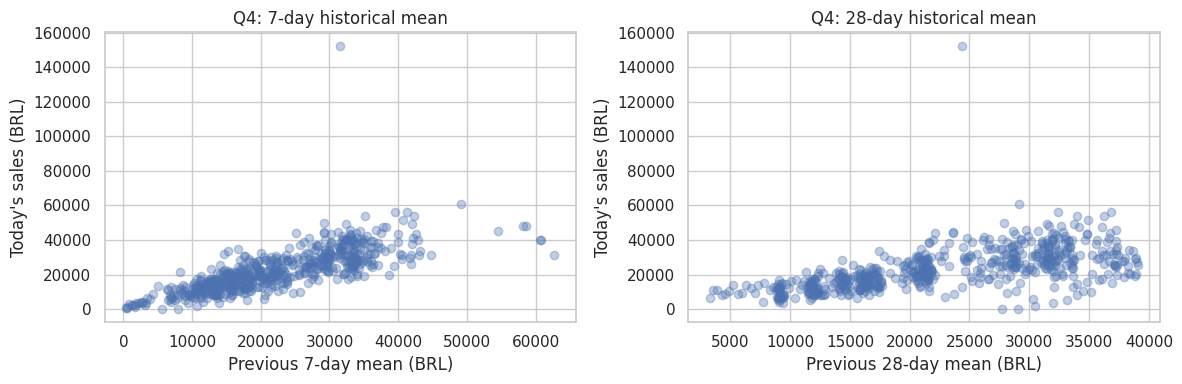

**Interpretation:** Correlations are 0.754 for the prior 7-day mean and 0.598 for the prior 28-day mean. The shorter window responds faster to change; the longer window smooths more strongly and may lag turning points. Scatter around each relationship indicates unpredictable daily variation. We test both as origin-time forecast features below.

In [11]:
past7 = daily.sales_value.shift(1).rolling(7).mean()
past28 = daily.sales_value.shift(1).rolling(28).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, days in zip(axes, [past7, past28], [7, 28]):
    ax.scatter(values, daily.sales_value, alpha=.35)
    ax.set(xlabel=f"Previous {days}-day mean (BRL)", ylabel="Today's sales (BRL)", title=f"Q4: {days}-day historical mean")
plt.tight_layout(); plt.show(); plt.close("all")
r7, r28 = daily.sales_value.corr(past7), daily.sales_value.corr(past28)
display(Markdown(f"**Interpretation:** Correlations are {r7:.3f} for the prior 7-day mean and {r28:.3f} for the prior 28-day mean. The shorter window responds faster to change; the longer window smooths more strongly and may lag turning points. Scatter around each relationship indicates unpredictable daily variation. We test both as origin-time forecast features below."))

### Q5. How does sales value relate to order volume and average order value?
These are internal business measures, not external variables. Same-day values explain sales retrospectively and are not available for forecasting that day.

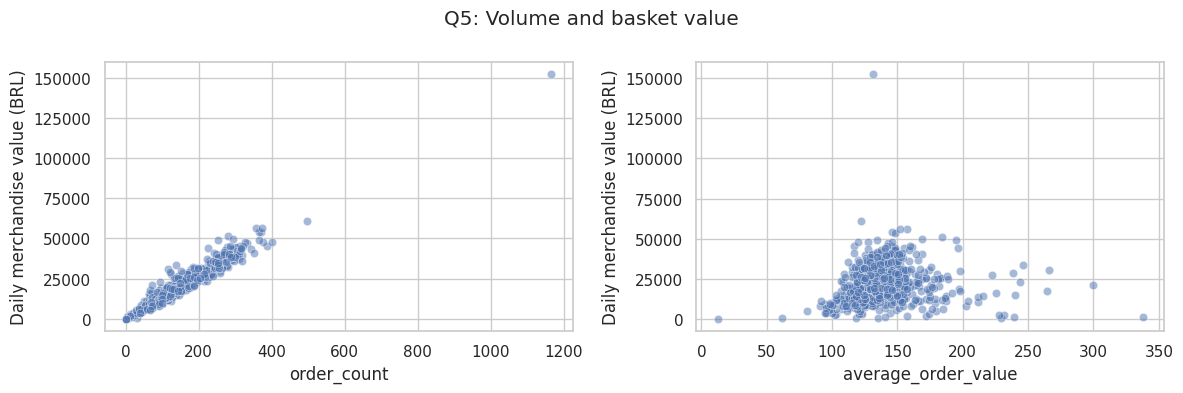

,sales_value,order_count,average_order_value
sales_value,1.000,0.966,0.095
order_count,0.966,1.000,-0.115
average_order_value,0.095,-0.115,1.000


**Interpretation:** Sales correlate 0.966 with order count and 0.095 with average order value. These associations are partly mathematical: sales equal count times average value for the included orders. They are not independent causal evidence. The forecasting model uses past order counts only, not future realized orders or basket values.

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["order_count", "average_order_value"]):
    sns.scatterplot(data=daily, x=col, y="sales_value", ax=ax, alpha=.5)
    ax.set_ylabel("Daily merchandise value (BRL)")
plt.suptitle("Q5: Volume and basket value"); plt.tight_layout(); plt.show(); plt.close("all")
correlations = daily[["sales_value", "order_count", "average_order_value"]].corr()
display(correlations.round(3))
display(Markdown(f"**Interpretation:** Sales correlate {correlations.loc['sales_value', 'order_count']:.3f} with order count and {correlations.loc['sales_value', 'average_order_value']:.3f} with average order value. These associations are partly mathematical: sales equal count times average value for the included orders. They are not independent causal evidence. The forecasting model uses past order counts only, not future realized orders or basket values."))

### Q6. Which days have unusually high sales relative to their recent history?
A descriptive flag compares sales to the previous 28-day mean plus three previous-window standard deviations. This is a heuristic, not a statistical significance test or a reason to remove observations.

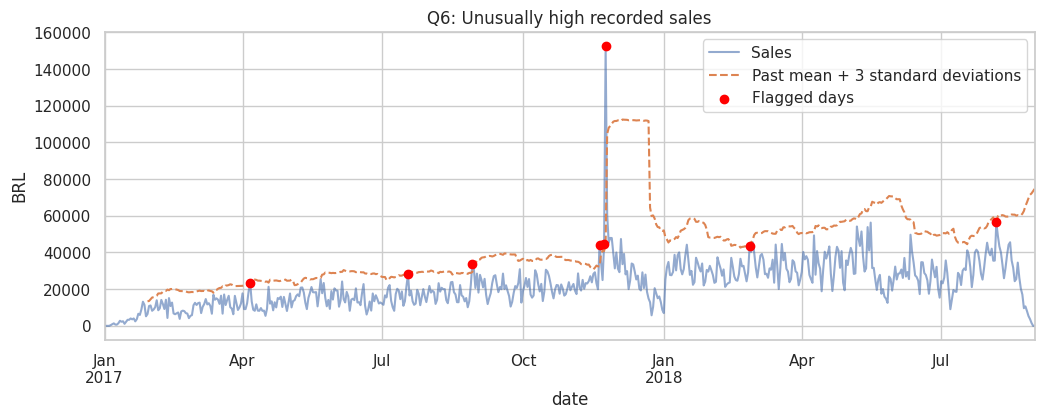

,sales_value,order_count,item_count,average_order_value
date,,,,
2017-11-24,152653.74,1166,1366.0,130.920875
2018-08-06,56427.39,372,430.0,151.686532
2017-11-23,44712.88,277,336.0,161.418339
2017-11-20,44284.47,226,262.0,195.948982
2018-02-26,43750.96,296,334.0,147.807297
2017-08-29,33756.48,137,155.0,246.397664
2017-07-18,28238.20,190,220.0,148.622105
2017-04-06,23168.89,95,110.0,243.883053


**Interpretation:** 8 days exceed this historical threshold after the initial 28-day warm-up. The highest recorded day is 2017-11-24, with BRL 152,653.74. Promotions, large orders, or recording issues are possible explanations, but the files alone do not confirm them. Keep genuine spikes and report their effect on forecast errors; do not label them as errors without investigation.

In [13]:
past_std = daily.sales_value.shift(1).rolling(28).std()
threshold = past28 + 3 * past_std
flags = daily.sales_value.gt(threshold) & threshold.notna()
ax = daily.sales_value.plot(figsize=(12, 4), alpha=.6, label="Sales")
threshold.plot(ax=ax, label="Past mean + 3 standard deviations", linestyle="--")
ax.scatter(daily.index[flags], daily.sales_value[flags], color="red", label="Flagged days", zorder=3)
plt.title("Q6: Unusually high recorded sales"); plt.ylabel("BRL"); plt.legend(); plt.show(); plt.close("all")
display(daily.loc[flags].sort_values("sales_value", ascending=False).head(10))
peak = daily.sales_value.idxmax()
display(Markdown(f"**Interpretation:** {int(flags.sum())} days exceed this historical threshold after the initial 28-day warm-up. The highest recorded day is {peak.date()}, with BRL {daily.loc[peak, 'sales_value']:,.2f}. Promotions, large orders, or recording issues are possible explanations, but the files alone do not confirm them. Keep genuine spikes and report their effect on forecast errors; do not label them as errors without investigation."))

## C. Train, tune, and evaluate a seven-day forecast

### 1. Define a leakage-safe forecasting experiment
At the end of each origin day, predict the **next seven daily sales values** directly. Each training row contains seven targets, so the random forest learns a multi-output forecast. The inputs are sales and order counts already observed by that origin, trailing averages, and known calendar values.

The last **28 calendar days** are held out for testing at four weekly origins. The preceding **28 days** form a validation period for comparing experiments. Earlier data train the candidate models. Three expanding time-series folds inside that training portion tune the random forest. A **seven-row gap** ensures earlier training targets do not overlap validation/test origins. No random split is used.

Earlier test-week observations may be used at later test origins: this simulates weekly forecasting as actual daily sales arrive. Model parameters remain fixed throughout the test period. The final test is opened only after selecting the experiment on validation MAE.

In [14]:
HORIZON = 7
y = daily.sales_value
X = pd.DataFrame(index=daily.index)
for lag in [0, 1, 6, 7, 13, 27]:
    X[f"sales_lag_{lag}"] = y.shift(lag)
for window in [7, 28]:
    X[f"sales_mean_{window}"] = y.rolling(window).mean()
    X[f"sales_std_{window}"] = y.rolling(window).std()
    X[f"orders_mean_{window}"] = daily.order_count.rolling(window).mean()
X["origin_weekday"] = X.index.dayofweek
X["next_day_weekday"] = (X.index + pd.Timedelta(days=1)).dayofweek
X["next_day_month"] = (X.index + pd.Timedelta(days=1)).month
X["time_index"] = np.arange(len(X))
Y = pd.concat({f"day_{h}": y.shift(-h) for h in range(1, HORIZON + 1)}, axis=1)
complete = X.notna().all(axis=1) & Y.notna().all(axis=1)
X, Y = X.loc[complete], Y.loc[complete]
test_start = daily.index[-28]
validation_start = test_start - pd.Timedelta(days=28)
train_mask = X.index + pd.Timedelta(days=7) < validation_start - pd.Timedelta(days=1)
validation_origins = pd.date_range(validation_start - pd.Timedelta(days=1), periods=4, freq="7D")
test_origins = pd.date_range(test_start - pd.Timedelta(days=1), periods=4, freq="7D")
X_train, Y_train = X.loc[train_mask], Y.loc[train_mask]
X_val, Y_val = X.loc[validation_origins], Y.loc[validation_origins]
X_test, Y_test = X.loc[test_origins], Y.loc[test_origins]
assert X_train.index.max() + pd.Timedelta(days=7) < X_val.index.min()
assert X_val.index.max() + pd.Timedelta(days=7) < test_start
print("Training origins:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Validation forecast dates:", validation_start.date(), "to", (test_start-pd.Timedelta(days=1)).date())
print("Test forecast dates:", test_start.date(), "to", daily.index.max().date())
print("Training rows:", len(X_train))

Training origins: 2017-01-28 to 2018-06-28
Validation forecast dates: 2018-07-07 to 2018-08-03
Test forecast dates: 2018-08-04 to 2018-08-31
Training rows: 517


### 2. Baseline and hyperparameter tuning
The seasonal-naive baseline repeats the seven days ending at each origin. It is essential for checking whether machine learning improves on a simple weekly pattern. Random forest is chosen for nonlinear relationships without requiring scaling. We tune tree depth and minimum leaf size across four combinations using training-only time-series cross-validation. CV MAE weights all seven forecast horizons equally. Overlapping forecast windows within CV create dependent errors, so CV scores are comparative estimates, not confidence intervals.

In [15]:
def seasonal_naive(origins):
    return np.vstack([y.loc[o-pd.Timedelta(days=6):o].to_numpy() for o in origins])

def metrics(actual, predicted):
    a, p = np.asarray(actual), np.asarray(predicted)
    return {"daily_MAE_BRL": mean_absolute_error(a.ravel(), p.ravel()),
            "daily_RMSE_BRL": np.sqrt(mean_squared_error(a.ravel(), p.ravel())),
            "weekly_total_MAE_BRL": mean_absolute_error(a.sum(axis=1), p.sum(axis=1))}

cv = TimeSeriesSplit(n_splits=3, gap=7)
for tr, va in cv.split(X_train):
    assert X_train.index[tr[-1]] + pd.Timedelta(days=7) < X_train.index[va[0]]
search = GridSearchCV(
    RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=1),
    param_grid={"max_depth": [6, None], "min_samples_leaf": [2, 7]},
    scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1, refit=True)
search.fit(X_train, Y_train)
cv_results = pd.DataFrame(search.cv_results_)
cv_results["CV_MAE_BRL"] = -cv_results.mean_test_score
cv_table = cv_results[["param_max_depth", "param_min_samples_leaf", "CV_MAE_BRL", "rank_test_score"]].sort_values("rank_test_score")
display(cv_table)
print("Best training-CV parameters:", search.best_params_)

,param_max_depth,param_min_samples_leaf,CV_MAE_BRL,rank_test_score
2,None,2,6708.827129,1
3,None,7,6712.998282,2
1,6,7,6718.438388,3
0,6,2,6721.370777,4


Best training-CV parameters: {'max_depth': None, 'min_samples_leaf': 2}


In [16]:
baseline_val = seasonal_naive(validation_origins)
forest_val = search.best_estimator_.predict(X_val)
experiment_table = pd.DataFrame([
    {"experiment": "Seasonal naive (repeat last week)", **metrics(Y_val, baseline_val)},
    {"experiment": "Tuned random forest", **metrics(Y_val, forest_val)}
]).set_index("experiment")
display(experiment_table.round(2))
use_forest = experiment_table.loc["Tuned random forest", "daily_MAE_BRL"] < experiment_table.iloc[0].daily_MAE_BRL
selected = "Tuned random forest" if use_forest else "Seasonal naive (repeat last week)"
display(Markdown(f"**Validation interpretation:** The selected experiment is **{selected}**, using the lower daily MAE across four validation weeks. MAE describes typical absolute error in BRL; RMSE penalizes large misses more strongly. Weekly-total MAE answers the business question directly, but daily MAE is the predeclared selection criterion. Four weeks is a small comparison sample, so this ranking may change in other periods."))

,daily_MAE_BRL,daily_RMSE_BRL,weekly_total_MAE_BRL
experiment,,,
Seasonal naive (repeat last week),7243.41,9204.99,40284.67
Tuned random forest,5020.77,6754.21,29058.16


**Validation interpretation:** The selected experiment is **Tuned random forest**, using the lower daily MAE across four validation weeks. MAE describes typical absolute error in BRL; RMSE penalizes large misses more strongly. Weekly-total MAE answers the business question directly, but daily MAE is the predeclared selection criterion. Four weeks is a small comparison sample, so this ranking may change in other periods.

### 3. Refit and evaluate the selected experiment on untouched test dates
After selecting the approach, refit the tuned forest using all labeled origins whose seven targets end before the test forecast origin. Evaluate only the selected approach on the held-out test period. Report horizon-specific errors as well as seven-day totals.

,daily_MAE_BRL,daily_RMSE_BRL,weekly_total_MAE_BRL
Tuned random forest,8922.56,11528.18,59307.75


,origin,actual_7day_total_BRL,predicted_7day_total_BRL
0,2018-08-03,293500.17,247102.24
1,2018-08-10,253266.43,244041.01
2,2018-08-17,157592.51,212965.11
3,2018-08-24,29235.98,155471.01


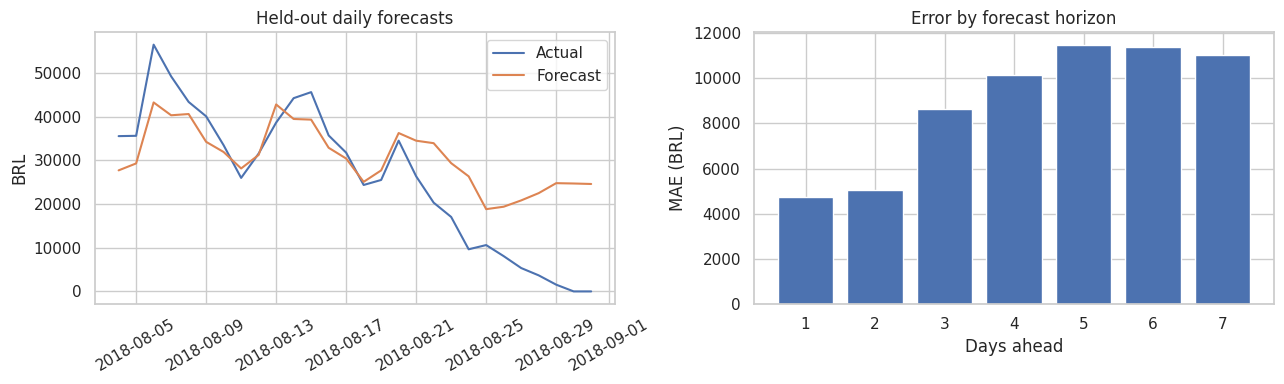

**Test interpretation:** The selected approach has daily MAE **BRL 8,922.56**, daily RMSE **BRL 11,528.18**, and seven-day-total MAE **BRL 59,307.75**. The line chart shows whether errors cluster around spikes or sustained changes. The horizon chart reveals which lead times were hardest in these four weeks. These results describe this held-out period only, not a guarantee of future accuracy.

In [17]:
refit_mask = X.index + pd.Timedelta(days=7) < test_origins[0]
final_model = None
if use_forest:
    final_model = RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1, **search.best_params_)
    final_model.fit(X.loc[refit_mask], Y.loc[refit_mask])
    test_prediction = final_model.predict(X_test)
else:
    test_prediction = seasonal_naive(test_origins)
test_metrics = metrics(Y_test, test_prediction)
display(pd.DataFrame([test_metrics], index=[selected]).round(2))
weekly_results = pd.DataFrame({"origin": test_origins,
    "actual_7day_total_BRL": Y_test.to_numpy().sum(axis=1),
    "predicted_7day_total_BRL": test_prediction.sum(axis=1)})
display(weekly_results.round(2))
horizon_mae = np.abs(Y_test.to_numpy() - test_prediction).mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
test_dates = pd.date_range(test_start, periods=28)
axes[0].plot(test_dates, Y_test.to_numpy().ravel(), label="Actual")
axes[0].plot(test_dates, test_prediction.ravel(), label="Forecast")
axes[0].set(title="Held-out daily forecasts", ylabel="BRL"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(range(1, 8), horizon_mae)
axes[1].set(title="Error by forecast horizon", xlabel="Days ahead", ylabel="MAE (BRL)")
plt.tight_layout(); plt.show(); plt.close("all")
display(Markdown(f"**Test interpretation:** The selected approach has daily MAE **BRL {test_metrics['daily_MAE_BRL']:,.2f}**, daily RMSE **BRL {test_metrics['daily_RMSE_BRL']:,.2f}**, and seven-day-total MAE **BRL {test_metrics['weekly_total_MAE_BRL']:,.2f}**. The line chart shows whether errors cluster around spikes or sustained changes. The horizon chart reveals which lead times were hardest in these four weeks. These results describe this held-out period only, not a guarantee of future accuracy."))

### 4. Save Task 1 outputs for the team
These artifacts support reproducibility and teammate handoff. This cell does not implement databases, endpoints, or a deployment forecast script. The saved model (when selected) is the model evaluated above, not a model refitted on the test period. Only load joblib files from trusted sources.

In [18]:
daily.to_csv(OUT / "daily_merchandise_sales.csv", index_label="date")
experiment_table.to_csv(OUT / "validation_experiments.csv")
cv_table.to_csv(OUT / "training_cv_results.csv", index=False)
weekly_results.to_csv(OUT / "test_weekly_totals.csv", index=False)
pd.DataFrame({"date": test_dates, "actual": Y_test.to_numpy().ravel(),
              "predicted": test_prediction.ravel()}).to_csv(OUT / "test_daily_predictions.csv", index=False)
if final_model is not None:
    joblib.dump(final_model, OUT / "selected_random_forest.joblib")
metadata = {"selected_experiment": selected, "horizon_days": 7,
    "target": "Daily recorded item-price sum by purchase date; excludes freight",
    "currency": "BRL", "window_start": str(START.date()), "window_end": str(END.date()),
    "test_start": str(test_start.date()), "features": list(X.columns),
    "best_forest_parameters": search.best_params_, "test_metrics": test_metrics,
    "versions": {"pandas": pd.__version__, "sklearn": sklearn.__version__},
    "forecast_origin": "End of day; that day's sales are available",
    "status_policy": "All statuses with valid items; not net realized revenue"}
(OUT / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved:", *[p.name for p in sorted(OUT.iterdir())], sep="\n")

Saved:
daily_merchandise_sales.csv
metadata.json
selected_random_forest.joblib
test_daily_predictions.csv
test_weekly_totals.csv
training_cv_results.csv
validation_experiments.csv


## Task 1 conclusions and limitations

- The event-level data provide a clear purchase timestamp, a derived monetary target, and several measurable variables over time.
- Daily aggregation preserves a regular forecasting axis; item-to-order aggregation prevents one-to-many join inflation.
- Six analytical questions are answered above with plots and numerical interpretations, including lag and moving-average analysis.
- The experiment table compares a seasonal baseline and a tuned multi-output random forest. Training-only time-series CV tunes parameters, validation selects the approach, and a held-out chronological period estimates its accuracy.
- Sales spikes, incomplete edge coverage, missing item values, and less than two full years of history limit generalization. Random forests also struggle to extrapolate beyond historical target ranges. There are no genuine external covariates such as advertising spend or weather in this analysis.
- For the PDF report, include the generated figures, the experiment and test tables, the rationale for cleaning decisions, and each teammate's actual contribution. Do not claim that this notebook implements Tasks 2–4.

**Handoff:** `daily_merchandise_sales.csv` contains `date`, `sales_value`, `order_count`, `item_count`, and `average_order_value`. See `metadata.json` for the target and modeling assumptions. Teammates should preserve these definitions when designing storage and APIs.

In [24]:

import shutil

# OUT is the folder containing your saved tables and model metadata.
output_dir = Path(OUT).resolve()

if not output_dir.is_dir():
    raise FileNotFoundError(f"Output folder not found: {output_dir}")

destination = Path("/content" if IS_COLAB else "/kaggle/working")
destination.mkdir(parents=True, exist_ok=True)
archive_base = destination / "olist_task1_outputs"

# Build elsewhere so the ZIP cannot include itself when OUT is destination.
import tempfile

with tempfile.TemporaryDirectory() as temp_dir:
    temporary_archive = shutil.make_archive(
        base_name=str(Path(temp_dir) / "olist_task1_outputs"),
        format="zip",
        root_dir=str(output_dir),
    )
    archive = shutil.move(
        temporary_archive,
        str(archive_base.with_suffix(".zip")),
    )

print(f"ZIP ready: {archive}")

if IS_COLAB:
    from google.colab import files
    files.download(archive)
else:
    print(
        "Kaggle: download olist_task1_outputs.zip from the Output section. "
        "Save a notebook version to retain the output."
    )


ZIP ready: /kaggle/working/olist_task1_outputs.zip
Kaggle: download olist_task1_outputs.zip from the Output section. Save a notebook version to retain the output.
